**CS 4140 – Deep Learning · L08 · Optimization for deep networks** &nbsp; [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Bolufe-Rohler/4140-deep-learning/blob/main/lectures/L08_optimization/L08_optimization.ipynb)

Run the first code cell before anything else. In Colab, *File → Save a copy in Drive* keeps your own changes.

In [ ]:
# ▶ Run this cell first. It gets the course code and this lecture's saved results and data,
#   in Google Colab or on your own computer.
LECTURE = "L08_optimization"
REPO = "https://github.com/Bolufe-Rohler/4140-deep-learning"
import os, sys, subprocess
root = os.path.abspath(os.path.join("..", ".."))
if not os.path.isfile(os.path.join(root, "cs4140_setup.py")):  # not inside the course repo (e.g. Colab)
    root = "/content/cs4140" if "google.colab" in sys.modules else os.path.abspath("cs4140")
    if not os.path.isdir(root):
        subprocess.run(["git", "clone", "--quiet", "--depth", "1", REPO, root], check=True)
    os.chdir(os.path.join(root, "lectures", LECTURE))
sys.path.insert(0, root)
import cs4140_setup
cs4140_setup.fetch_assets(LECTURE)

# CS 4140 · Lecture 8 · Optimization: Rolling Downhill in a Million Dimensions

Companion notebook for the slides. Every number and every figure in the deck comes from this notebook.

| Experiment | Slide idea | Full run (2 CPU cores) |
|---|---|---|
| 1. Three learning rates | the hook: one crawls, one learns, one explodes | ~10 s |
| 2. The batch-size race | same 8 seconds of CPU for batch sizes 50,000 / 1,000 / 64 / 1 | ~5 min |
| 3. Exponentially weighted averages | Charlottetown's 2025 daily temperatures | <1 s |
| 4. The optimizer race on a ravine | GD, momentum, RMSProp and Adam on a 2-D bowl | <1 s |
| 5. Optimizers on Fashion-MNIST | a learning-rate sweep, then a 5-epoch race | ~4 min |
| 6. Learning-rate decay | constant vs step vs cosine for SGD | ~1.5 min |
| 7. Saddles vs minima | how often a random critical point is a minimum | ~5 s |

**Class mode** (`CLASS_MODE = True`, the default) loads the saved results in `results/` and only redraws the figures (about 10 s).
Set `CLASS_MODE = False` to re-run every experiment from scratch (about 8 minutes on a laptop CPU, no GPU needed).

Network used throughout: the Fashion-MNIST network from Jan 15 / Jan 20 (784 → 128 → 10, ReLU, 101,770 parameters).
Data: 50,000 training images, 10,000 validation images (both from the official training set). The official test set is not used today.

In [1]:
CLASS_MODE = True          # False = re-run all experiments (~8 min on CPU)
DATA_DIR = './data'        # Fashion-MNIST is downloaded here on first use (~30 MB)

import json, math, time, os, csv, urllib.request
import numpy as np
import torch, torch.nn as nn, torchvision
import matplotlib
import matplotlib.pyplot as plt

torch.set_num_threads(max(1, os.cpu_count() or 1))
os.makedirs('results', exist_ok=True); os.makedirs('figures', exist_ok=True); os.makedirs('figures/slides', exist_ok=True)

# ---- slide style: Century Schoolbook (or its free twin, TeX Gyre Schola), the course palette
matplotlib.rcParams.update({
    'font.family': 'serif', 'font.serif': ['Century Schoolbook', 'TeX Gyre Schola', 'DejaVu Serif'],
    'mathtext.fontset': 'dejavuserif', 'font.size': 16, 'axes.titlesize': 18, 'axes.labelsize': 17,
    'xtick.labelsize': 14, 'ytick.labelsize': 14, 'legend.fontsize': 14, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.edgecolor': '#333333', 'axes.linewidth': 1.2, 'savefig.dpi': 200})
BLUE, RED, GOLD, TEAL, GRAY, NAVY = '#2B47C7', '#D62728', '#C98A00', '#2CA58D', '#6E6E6E', '#000080'


def layered(name, size, rect, setup, layers):
    """Save a base figure (axes only) plus one transparent PNG per layer with identical geometry,
    so the slides can reveal each curve on its own click. Also saves the combined figure."""
    def new():
        fig = plt.figure(figsize=size); ax = fig.add_axes(rect); setup(ax); return fig, ax
    fig, ax = new(); fig.savefig(f'figures/slides/{name}_base.png', transparent=False, facecolor='white'); plt.close(fig)
    for lname, draw in layers:
        fig, ax = new(); draw(ax)
        ax.patch.set_alpha(0); [s.set_visible(False) for s in ax.spines.values()]
        ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(''); ax.set_ylabel(''); ax.set_title('')
        for t in list(ax.texts):
            if getattr(t, '_base', False): t.remove()
        fig.savefig(f'figures/slides/{name}_{lname}.png', transparent=True); plt.close(fig)
    fig, ax = new()
    for lname, draw in layers: draw(ax)
    fig.savefig(f'figures/{name}.png', facecolor='white'); plt.show(); plt.close(fig)


def save_json(obj, path):
    with open(path, 'w') as f: json.dump(obj, f)


def load_json(path):
    with open(path) as f: return json.load(f)


def need(path):
    """True when the experiment must run (full mode, or no saved result yet)."""
    return (not CLASS_MODE) or (not os.path.exists(path))

## Data and the network

In [2]:
def load_fmnist(root=DATA_DIR):
    tr = torchvision.datasets.FashionMNIST(root, train=True, download=True)
    X = ((tr.data.float() / 255. - 0.2860) / 0.3530).unsqueeze(1)
    return X, tr.targets.clone()


def mlp():
    return nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10))


@torch.no_grad()
def evaluate(m, X, y, bs=5000):
    m.eval(); lf = nn.CrossEntropyLoss(reduction='sum'); L = 0.; c = 0
    for i in range(0, len(X), bs):
        o = m(X[i:i + bs]); L += lf(o, y[i:i + bs]).item(); c += (o.argmax(1) == y[i:i + bs]).sum().item()
    m.train(); return L / len(X), c / len(X)


def train(opt_fn, epochs=2, bs=64, seed=0, sched_fn=None):
    """Plain minibatch training loop. Returns per-step losses and per-epoch validation (loss, acc)."""
    torch.manual_seed(seed); m = mlp(); opt = opt_fn(m.parameters()); lf = nn.CrossEntropyLoss()
    sch = sched_fn(opt) if sched_fn else None
    g = torch.Generator().manual_seed(seed + 1000)
    losses, val = [], []
    for ep in range(epochs):
        perm = torch.randperm(len(Xtr), generator=g)
        for i in range(0, len(Xtr), bs):
            idx = perm[i:i + bs]
            loss = lf(m(Xtr[idx]), ytr[idx]); opt.zero_grad(); loss.backward(); opt.step()
            if sch: sch.step()
            l = loss.item(); losses.append(l if math.isfinite(l) else float('nan'))
            if not math.isfinite(l):
                return dict(losses=losses, val=val + [(float('nan'), 0.1)], diverged=True)
        val.append(evaluate(m, Xv, yv))
    return dict(losses=losses, val=val, diverged=False)


X, y = load_fmnist()
Xtr, ytr, Xv, yv = X[:50000], y[:50000], X[50000:], y[50000:]
print('train', tuple(Xtr.shape), 'val', tuple(Xv.shape), '| parameters:', sum(p.numel() for p in mlp().parameters()))

train (50000, 1, 28, 28) val (10000, 1, 28, 28) | parameters: 101770


## Experiment 1 · Same network, same data, three learning rates
Plain SGD, minibatches of 64, two epochs (the Jan 20 setup used lr = 0.1). Only the learning rate changes.

lr=0.001  steps= 1564 diverged=False  final val acc=0.741
lr=0.1    steps= 1564 diverged=False  final val acc=0.857
lr=1.0    steps= 1564 diverged=False  final val acc=0.283


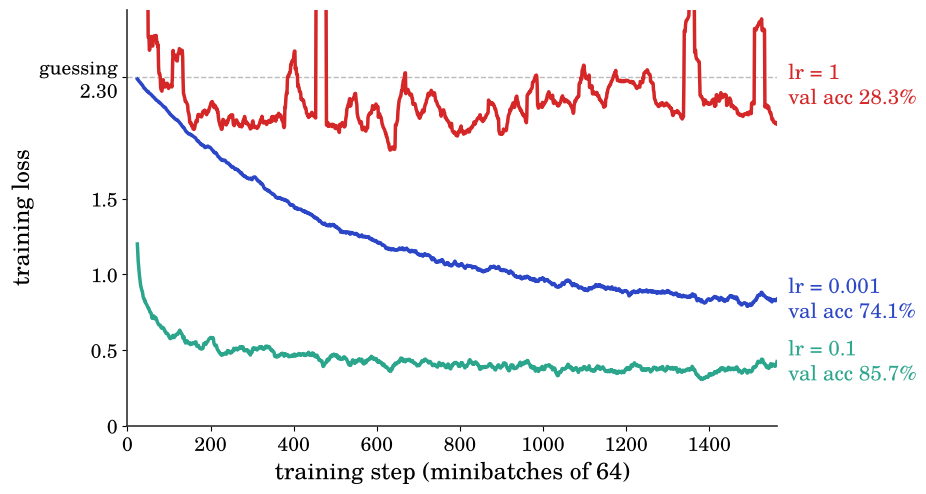

In [3]:
P1 = 'results/e1_three_lrs.json'
LRS_HOOK = [0.001, 0.1, 1.0]
if need(P1):
    e1 = {str(lr): train(lambda p, lr=lr: torch.optim.SGD(p, lr=lr), epochs=2) for lr in LRS_HOOK}
    save_json(e1, P1)
e1 = load_json(P1)
for lr in LRS_HOOK:
    r = e1[str(lr)]
    print(f"lr={lr:<6} steps={len(r['losses']):5d} diverged={r['diverged']!s:5}  final val acc={r['val'][-1][1]:.3f}")


def smooth(v, k=25):
    v = np.array(v, float); out = np.convolve(v, np.ones(k) / k, mode='valid'); return np.arange(k - 1, len(v)), out


def setup_hook(ax):
    ax.set_xlim(0, 1564); ax.set_ylim(0, 2.75); ax.set_xlabel('training step (minibatches of 64)'); ax.set_ylabel('training loss')
    ax.axhline(math.log(10), color='#BBBBBB', lw=1, ls='--')
    ax.set_yticks([0, 0.5, 1.0, 1.5, math.log(10)]); ax.set_yticklabels(['0', '0.5', '1.0', '1.5', 'guessing\n2.30'])


def hook_layer(lr, color, label):
    def draw(ax):
        r = e1[str(lr)]
        s, v = smooth(r['losses'], k=25)
        ax.plot(s, v, color=color, lw=2.5)
        if r['diverged'] or np.nanmean(r['losses'][-100:]) > 3:
            ax.annotate(f"{label}: the loss explodes\n(≈{np.nanmean(r['losses'][-100:]):,.0f} after 2 epochs)", xy=(20, 2.55), xytext=(150, 2.2),
                        color=color, fontsize=15, arrowprops=dict(arrowstyle='->', color=color))
        elif lr >= 1:
            ax.text(1590, 2.25, f"{label}\nval acc {r['val'][-1][1]*100:.1f}%", color=color, ha='left', va='center', fontsize=15)
        else:
            ax.text(1590, v[-1], f"{label}\nval acc {r['val'][-1][1]*100:.1f}%", color=color, ha='left', va='center', fontsize=15)
    return draw


layered('l08_hook_three_lrs', (10, 5.2), [0.145, 0.15, 0.65, 0.8], setup_hook,
        [('lr0001', hook_layer(0.001, BLUE, 'lr = 0.001')), ('lr01', hook_layer(0.1, TEAL, 'lr = 0.1')), ('lr1', hook_layer(1.0, RED, 'lr = 1'))])

## Experiment 2 · The batch-size race: 8 seconds of CPU each
Each batch size gets the same wall-clock budget. To be fair, each first gets its own best learning rate from a
small sweep (0.003 … 1, 8 s each, one seed); then three seeds at that learning rate. Validation accuracy is measured
on 2,000 validation images along the way (evaluation time is not counted) and on all 10,000 at the end.
Your laptop will take a different number of steps; the ranking is what matters.

batch  50000  best lr 0.3    steps in 8 s:       32  epochs: 32.00  val acc: 73.8%
batch   1000  best lr 0.3    steps in 8 s:     1601  epochs: 32.03  val acc: 88.7%
batch     64  best lr 0.3    steps in 8 s:     9061  epochs: 11.60  val acc: 87.7%
batch      1  best lr 0.003  steps in 8 s:    14744  epochs:  0.29  val acc: 83.6%


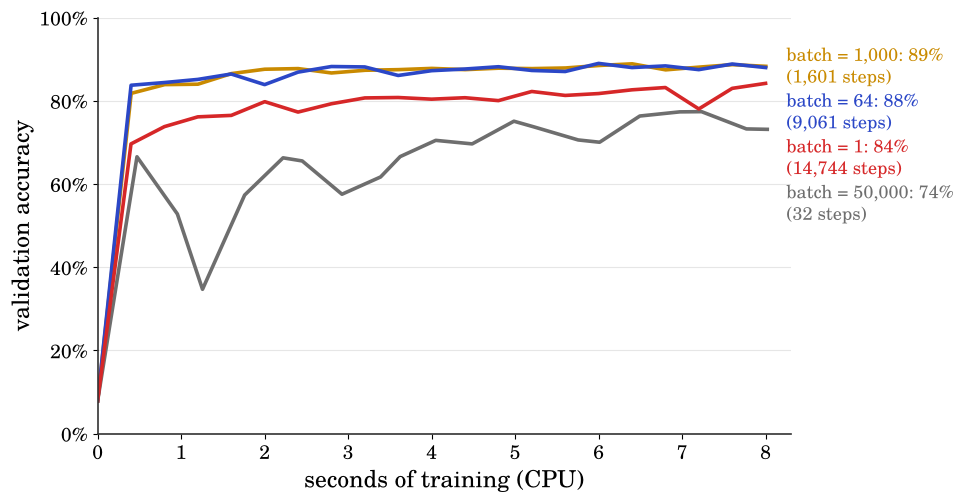

In [4]:
P2 = 'results/e2_batch_race.json'
BATCHES, LR_GRID = [50000, 1000, 64, 1], [0.003, 0.01, 0.03, 0.1, 0.3, 1.0]


def race(bs, lr, budget=8.0, seed=0, every=0.4):
    torch.manual_seed(seed); m = mlp(); opt = torch.optim.SGD(m.parameters(), lr=lr); lf = nn.CrossEntropyLoss()
    g = torch.Generator().manual_seed(seed + 1000); Xs, ys = Xv[:2000], yv[:2000]
    t_train, steps, curve, nxt = 0.0, 0, [(0.0, evaluate(m, Xs, ys)[1])], every
    while t_train < budget:
        perm = torch.randperm(len(Xtr), generator=g)
        for i in range(0, len(Xtr), bs):
            t = time.time(); idx = perm[i:i + bs]
            loss = lf(m(Xtr[idx]), ytr[idx]); opt.zero_grad(); loss.backward(); opt.step(); steps += 1
            t_train += time.time() - t
            if not math.isfinite(loss.item()):
                return dict(curve=curve, steps=steps, epochs=steps * bs / len(Xtr), final=0.1, diverged=True)
            if t_train >= nxt: curve.append((t_train, evaluate(m, Xs, ys)[1])); nxt += every
            if t_train >= budget: break
    return dict(curve=curve, steps=steps, epochs=steps * bs / len(Xtr), final=evaluate(m, Xv, yv)[1], diverged=False)


if need(P2):
    sweep2 = {str(bs): {str(lr): race(bs, lr)['final'] for lr in LR_GRID} for bs in BATCHES}
    best2 = {bs: max(LR_GRID, key=lambda lr: sweep2[str(bs)][str(lr)]) for bs in BATCHES}
    e2 = {'sweep': sweep2, 'best_lr': {str(b): l for b, l in best2.items()},
          'runs': {str(bs): [race(bs, best2[bs], seed=s) for s in range(3)] for bs in BATCHES}}
    save_json(e2, P2)
E2 = load_json(P2); e2 = E2['runs']; RACE = [(bs, E2['best_lr'][str(bs)]) for bs in BATCHES]
for bs, lr in RACE:
    rs = e2[str(bs)]
    print(f"batch {bs:>6}  best lr {lr:<6} steps in 8 s: {np.mean([r['steps'] for r in rs]):8.0f}  "
          f"epochs: {np.mean([r['epochs'] for r in rs]):5.2f}  val acc: {np.mean([r['final'] for r in rs])*100:.1f}%")


def setup_race(ax):
    ax.set_xlim(0, 8.3); ax.set_ylim(0, 1.0); ax.set_xlabel('seconds of training (CPU)'); ax.set_ylabel('validation accuracy')
    ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0)); ax.grid(axis='y', color='#E6E6E6')


ends = {bs: e2[str(bs)][0]['curve'][-1][1] for bs in BATCHES}
lab_y, last = {}, None
for bs in sorted(BATCHES, key=lambda b: -ends[b]):          # spread the end labels at least 0.11 apart
    y_ = ends[bs] if last is None else min(ends[bs], last - 0.11); lab_y[bs] = y_; last = y_


def race_layer(bs, color, label):
    def draw(ax):
        r = e2[str(bs)][0]; t, a = zip(*r['curve']); ax.plot(t, a, color=color, lw=2.6)
        st = np.mean([q['steps'] for q in e2[str(bs)]]); fin = np.mean([q['final'] for q in e2[str(bs)]])
        ax.text(8.25, lab_y[bs], f"{label}: {fin*100:.0f}%\n({st:,.0f} steps)", color=color, fontsize=13, va='center', ha='left')
    return draw


layered('l08_batch_race', (10.5, 5.2), [0.09, 0.15, 0.66, 0.8], setup_race,
        [('full', race_layer(50000, GRAY, 'batch = 50,000')), ('b1000', race_layer(1000, GOLD, 'batch = 1,000')),
         ('b64', race_layer(64, BLUE, 'batch = 64')), ('b1', race_layer(1, RED, 'batch = 1'))])

## Experiment 3 · Exponentially weighted averages: Charlottetown, 2025
Daily mean temperature at Charlottetown A (ECCC climate ID 8300301). 24 days have no reading; the average simply
skips them. v₀ = 0 and vₜ = β·vₜ₋₁ + (1 − β)·xₜ.

365 days, 341 with a reading; first three: [ 1.1  3.1 -3. ] | day 120: [10.3] | day 290: [11.6]


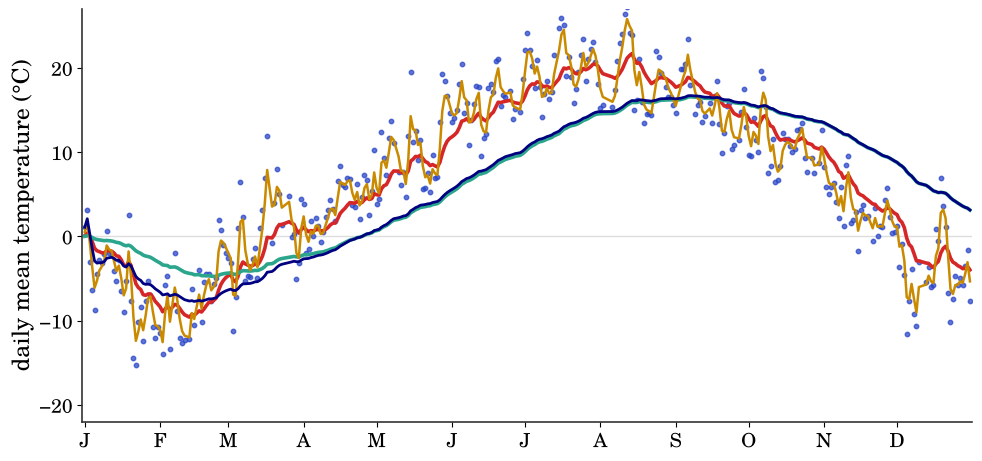

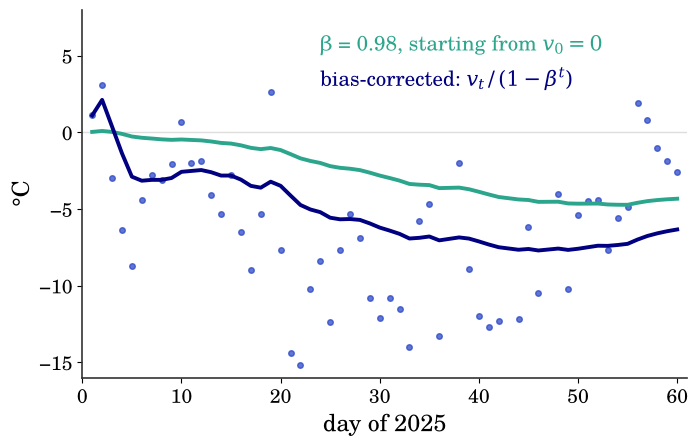

In [5]:
CSV = 'data/charlottetown_A_daily_2025.csv'
if not os.path.exists(CSV):
    url = ('https://climate.weather.gc.ca/climate_data/bulk_data_e.html?format=csv&stationID=50621'
           '&Year=2025&Month=1&Day=1&timeframe=2&submit=Download+Data')
    os.makedirs('data', exist_ok=True); urllib.request.urlretrieve(url, CSV)
rows = list(csv.DictReader(open(CSV, encoding='utf-8-sig')))
day = np.array([i + 1 for i, r in enumerate(rows) if r['Mean Temp (°C)'] != ''])
temp = np.array([float(r['Mean Temp (°C)']) for r in rows if r['Mean Temp (°C)'] != ''])
print(len(rows), 'days,', len(temp), 'with a reading; first three:', temp[:3], '| day 120:', temp[day == 120], '| day 290:', temp[day == 290])


def ewa(x, beta, correct=False):
    v, out = 0.0, []
    for t, xt in enumerate(x, 1):
        v = beta * v + (1 - beta) * xt; out.append(v / (1 - beta ** t) if correct else v)
    return np.array(out)


ew = {b: ewa(temp, b) for b in (0.9, 0.98, 0.5)}
ew['0.98c'] = ewa(temp, 0.98, correct=True)
save_json({'day': day.tolist(), 'temp': temp.tolist(), **{str(k): v.tolist() for k, v in ew.items()}}, 'results/e3_ewa_charlottetown.json')
MONTHS = [1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335]


def setup_ewa(ax):
    ax.set_xlim(0, 366); ax.set_ylim(-22, 27); ax.set_ylabel('daily mean temperature (°C)')
    ax.set_xticks(MONTHS); ax.set_xticklabels(list('JFMAMJJASOND')); ax.axhline(0, color='#DDDDDD', lw=1)


def dots(ax): ax.plot(day, temp, 'o', color=BLUE, ms=3.2, alpha=0.75)


def line(b, color, lw=2.6):
    def draw(ax): ax.plot(day, ew[b], color=color, lw=lw)
    return draw


layered('l08_ewa', (10, 4.8), [0.09, 0.1, 0.89, 0.86], setup_ewa,
        [('dots', dots), ('b09', line(0.9, RED)), ('b098', line(0.98, TEAL)), ('b05', line(0.5, GOLD, 1.8)), ('b098c', line('0.98c', NAVY, 2.0))])

# Data-only, cumulative layers that drop straight into the hand-drawn axes of the original EWA slides
HIS = {'dots': '#1B3FFF', 0.9: '#E8432A', 0.98: '#3DAA35', 0.5: '#D4A000'}
stack = [('dots', []), ('red', [0.9]), ('green', [0.9, 0.98]), ('gold', [0.9, 0.98, 0.5])]
for name, betas in stack:
    fig = plt.figure(figsize=(7.68, 3.6)); ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(-3, 368); ax.set_ylim(-24, 27); ax.axis('off')
    ax.plot(day, temp, 'o', color=HIS['dots'], ms=4.2)
    for b in betas: ax.plot(day, ew[b], color=HIS[b], lw=4.2 if b != 0.5 else 3.0)
    fig.savefig(f'figures/slides/l08_ewa_his_{name}.png', transparent=True, dpi=300); plt.close(fig)

# Bias correction close-up: the first 60 days with beta = 0.98
def setup_bias(ax):
    ax.set_xlim(0, 61); ax.set_ylim(-16, 8); ax.set_xlabel('day of 2025'); ax.set_ylabel('°C'); ax.axhline(0, color='#DDDDDD', lw=1)


def bias_dots(ax):
    m = day <= 60; ax.plot(day[m], temp[m], 'o', color=BLUE, ms=4, alpha=0.75)


def bias_line(k, color, label, xy):
    def draw(ax):
        m = day <= 60; ax.plot(day[m], ew[k][m], color=color, lw=2.8); ax.text(*xy, label, color=color, fontsize=15, ha='left')
    return draw


layered('l08_bias', (7.2, 4.6), [0.13, 0.15, 0.84, 0.8], setup_bias,
        [('dots', bias_dots), ('raw', bias_line(0.98, TEAL, r'β = 0.98, starting from $v_0 = 0$', (24, 5.3))),
         ('corrected', bias_line('0.98c', NAVY, r'bias-corrected: $v_t\,/\,(1-\beta^t)$', (24, 3.0)))])

## Experiment 4 · The optimizer race on a ravine
f(w₁, w₂) = ½(0.08·w₁² + 4·w₂²): a long, narrow valley (50× steeper across than along). Everyone starts at (−9, 1.6)
and gets 30 steps. Momentum is written the way PyTorch does it (v ← βv + g; the course slides use the
equivalent (1 − β) form with a 10× larger α).

GD        lr=0.45  after 30 steps: w=( -3.00,  0.00)  f=0.3591   distance to min=3.00
Momentum  lr=0.2   after 30 steps: w=( -0.17, -0.01)  f=0.0012   distance to min=0.17
RMSProp   lr=0.3   after 30 steps: w=( -0.80,  0.00)  f=0.0258   distance to min=0.80
Adam      lr=0.4   after 30 steps: w=(  0.37, -0.19)  f=0.0803   distance to min=0.41


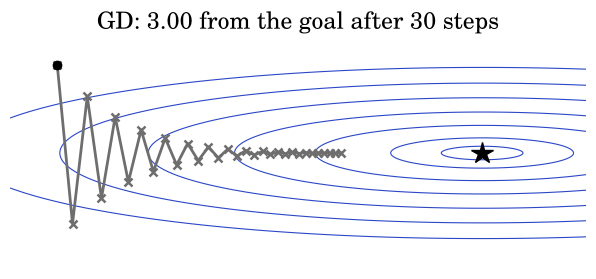

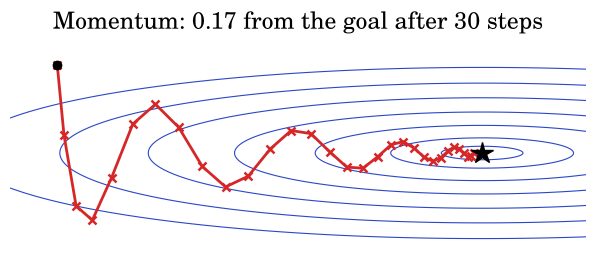

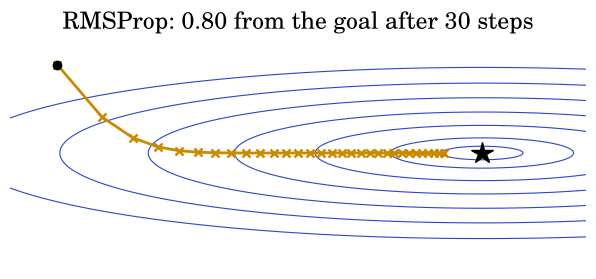

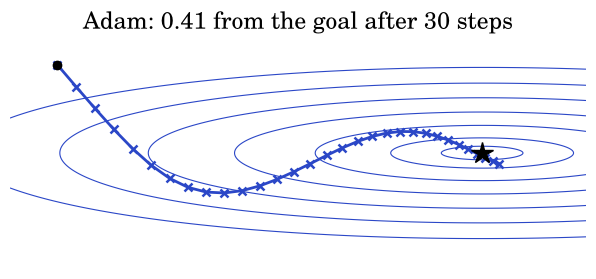

In [6]:
A_, B_ = 0.08, 4.0
f2 = lambda w: 0.5 * (A_ * w[0] ** 2 + B_ * w[1] ** 2)
g2 = lambda w: np.array([A_ * w[0], B_ * w[1]])


def run2d(kind, lr, steps=30, beta=0.8, beta2=0.9, eps=1e-8, w0=(-9.0, 1.6)):
    w = np.array(w0, float); v = np.zeros(2); s = np.zeros(2); P = [w.copy()]
    for t in range(1, steps + 1):
        g = g2(w)
        if kind == 'GD': w = w - lr * g
        elif kind == 'Momentum': v = beta * v + g; w = w - lr * v
        elif kind == 'RMSProp': s = beta2 * s + (1 - beta2) * g * g; w = w - lr * g / (np.sqrt(s) + eps)
        elif kind == 'Adam':
            v = 0.9 * v + 0.1 * g; s = 0.999 * s + 0.001 * g * g
            w = w - lr * (v / (1 - 0.9 ** t)) / (np.sqrt(s / (1 - 0.999 ** t)) + eps)
        P.append(w.copy())
    return np.array(P)


CFG2 = [('GD', 0.45, GRAY), ('Momentum', 0.2, RED), ('RMSProp', 0.3, GOLD), ('Adam', 0.4, BLUE)]
paths = {k: run2d(k, lr) for k, lr, _ in CFG2}
for k, lr, _ in CFG2:
    print(f'{k:9s} lr={lr:<5} after 30 steps: w=({paths[k][-1][0]:6.2f},{paths[k][-1][1]:6.2f})  f={f2(paths[k][-1]):.4f}   distance to min={np.linalg.norm(paths[k][-1]):.2f}')
save_json({k: {'lr': lr, 'path': paths[k].tolist(), 'f_final': float(f2(paths[k][-1]))} for k, lr, _ in CFG2}, 'results/e4_ravine_race.json')

W1, W2 = np.meshgrid(np.linspace(-10, 2.2, 300), np.linspace(-2.1, 2.1, 300))
for k, lr, color in CFG2:
    fig = plt.figure(figsize=(6, 2.9)); ax = fig.add_axes([0.02, 0.04, 0.96, 0.8])
    ax.contour(W1, W2, 0.5 * (A_ * W1 ** 2 + B_ * W2 ** 2), levels=[0.03, 0.15, 0.5, 1.1, 2.0, 3.2, 4.8], colors=BLUE, linewidths=0.8)
    P = paths[k]; ax.plot(P[:, 0], P[:, 1], '-', color=color, lw=2); ax.plot(P[:, 0], P[:, 1], 'x', color=color, ms=6, mew=1.8)
    ax.plot(0, 0, '*', color='black', ms=16); ax.plot(-9, 1.6, 'o', color='black', ms=6)
    ax.set_xlim(-10, 2.2); ax.set_ylim(-2.1, 2.1); ax.set_xticks([]); ax.set_yticks([])
    [s.set_visible(False) for s in ax.spines.values()]
    ax.set_title(f'{k}: {np.linalg.norm(P[-1]):.2f} from the goal after 30 steps', fontsize=17, color='black')
    fig.savefig(f'figures/slides/l08_ravine_{k}.png', facecolor='white'); plt.show(); plt.close(fig)

## Experiment 5 · Optimizers on Fashion-MNIST
(a) A learning-rate sweep: 12 learning rates from 10⁻⁵ to 3, two epochs, one seed, for each optimizer.
(b) A race: each optimizer at the best learning rate from the sweep, five epochs, three seeds.

SGD       best lr 0.1     val acc 85.7%   lrs with ≥ 84%: [0.03, 0.1, 0.3]
Momentum  best lr 0.01    val acc 86.4%   lrs with ≥ 84%: [0.003, 0.01, 0.03]
RMSProp   best lr 0.001   val acc 86.4%   lrs with ≥ 84%: [0.0001, 0.0003, 0.001, 0.003]
Adam      best lr 0.001   val acc 86.8%   lrs with ≥ 84%: [0.0003, 0.001, 0.003, 0.01]
SGD       lr 0.1     val acc by epoch (mean of 3 seeds): [77.8 85.  86.5 85.5 85.9]
Momentum  lr 0.01    val acc by epoch (mean of 3 seeds): [85.4 86.2 86.7 87.4 88.1]
RMSProp   lr 0.001   val acc by epoch (mean of 3 seeds): [80.5 86.1 87.6 86.2 86.8]
Adam      lr 0.001   val acc by epoch (mean of 3 seeds): [85.6 86.4 86.9 87.8 88.2]


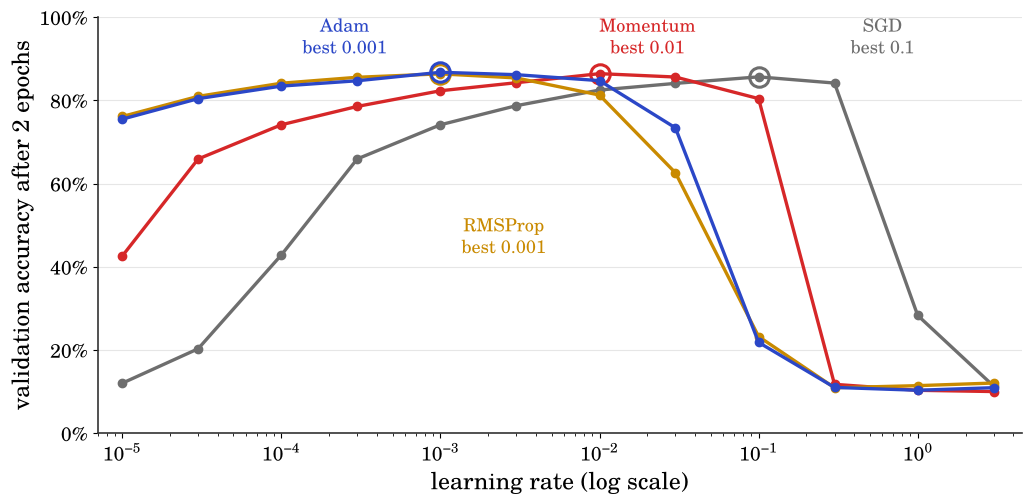

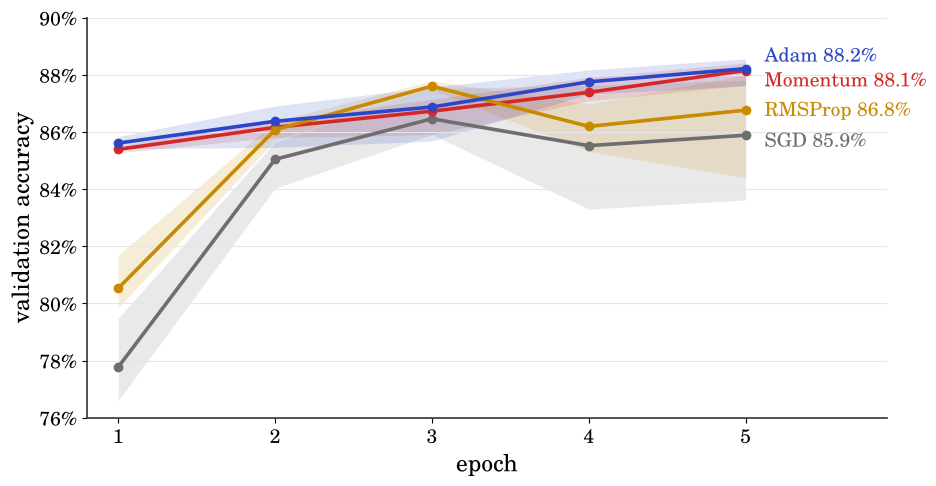

In [7]:
P5a, P5b = 'results/e5a_lr_sweep.json', 'results/e5b_optimizer_race.json'
OPTS = {'SGD': lambda lr: (lambda p: torch.optim.SGD(p, lr=lr)),
        'Momentum': lambda lr: (lambda p: torch.optim.SGD(p, lr=lr, momentum=0.9)),
        'RMSProp': lambda lr: (lambda p: torch.optim.RMSprop(p, lr=lr)),
        'Adam': lambda lr: (lambda p: torch.optim.Adam(p, lr=lr))}
LRS = [1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 0.1, 0.3, 1.0, 3.0]
if need(P5a):
    e5a = {k: [train(f(lr), epochs=2)['val'][-1][1] for lr in LRS] for k, f in OPTS.items()}
    save_json({'lrs': LRS, 'acc': e5a}, P5a)
e5a = load_json(P5a)['acc']
BEST = {k: LRS[int(np.argmax(v))] for k, v in e5a.items()}
for k, v in e5a.items():
    print(f"{k:9s} best lr {BEST[k]:<7} val acc {max(v)*100:.1f}%   lrs with ≥ 84%: {[lr for lr, a in zip(LRS, v) if a >= 0.84]}")

if need(P5b):
    e5b = {k: [train(OPTS[k](BEST[k]), epochs=5, seed=s) for s in range(3)] for k in OPTS}
    save_json(e5b, P5b)
e5b = load_json(P5b)
for k in OPTS:
    va = np.array([[v[1] for v in r['val']] for r in e5b[k]])
    print(f"{k:9s} lr {BEST[k]:<7} val acc by epoch (mean of 3 seeds): {np.round(va.mean(0)*100, 1)}")

COLS = {'SGD': GRAY, 'Momentum': RED, 'RMSProp': GOLD, 'Adam': BLUE}


def setup_sweep(ax):
    ax.set_xscale('log'); ax.set_xlim(7e-6, 4.5); ax.set_ylim(0, 1.0); ax.set_xlabel('learning rate (log scale)')
    ax.set_ylabel('validation accuracy after 2 epochs'); ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
    ax.grid(axis='y', color='#E6E6E6')


def sweep_layer(k):
    def draw(ax):
        v = e5a[k]; ax.plot(LRS, v, 'o-', color=COLS[k], lw=2.4, ms=6)
        i = int(np.argmax(v)); ax.plot(LRS[i], v[i], 'o', ms=14, mfc='none', mec=COLS[k], mew=2.2)
        pos = {'SGD': (0.6, 0.9), 'Momentum': (0.02, 0.9), 'RMSProp': (2.5e-3, 0.42), 'Adam': (2.5e-4, 0.9)}[k]
        ax.text(*pos, f'{k}\nbest {LRS[i]:g}', color=COLS[k], fontsize=13, ha='center', va='bottom')
    return draw


layered('l08_lr_sweep', (10.5, 5.2), [0.09, 0.15, 0.88, 0.8], setup_sweep, [(k, sweep_layer(k)) for k in ['SGD', 'Momentum', 'RMSProp', 'Adam']])


def setup_race5(ax):
    ax.set_xlim(0.8, 5.9); ax.set_ylim(0.76, 0.90); ax.set_xticks([1, 2, 3, 4, 5]); ax.set_xlabel('epoch')
    ax.set_ylabel('validation accuracy'); ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0, decimals=0))
    ax.grid(axis='y', color='#E6E6E6')


def race5_layer(k):
    def draw(ax):
        va = np.array([[v[1] for v in r['val']] for r in e5b[k]]); e = np.arange(1, 6)
        ax.fill_between(e, va.min(0), va.max(0), color=COLS[k], alpha=0.15, lw=0)
        ax.plot(e, va.mean(0), 'o-', color=COLS[k], lw=2.6, ms=6)
        dy = {'SGD': -0.002, 'Momentum': -0.0035, 'RMSProp': 0.0, 'Adam': 0.0045}[k]
        ax.text(5.12, va.mean(0)[-1] + dy, f'{k} {va.mean(0)[-1]*100:.1f}%', color=COLS[k], fontsize=14, va='center')
    return draw


layered('l08_fmnist_race', (10, 5.0), [0.1, 0.15, 0.8, 0.8], setup_race5, [(k, race5_layer(k)) for k in ['SGD', 'Momentum', 'RMSProp', 'Adam']])

## Experiment 6 · Learning-rate decay
SGD at lr 0.1 for five epochs (three seeds): constant, step decay (×0.1 every 2 epochs), and cosine decay to zero.

constant  final val acc per seed: [83.6 87.8 86.2]  mean 85.9%   by epoch: [77.8 85.  86.5 85.5 85.9]
step      final val acc per seed: [87.9 87.8 87.9]  mean 87.9%   by epoch: [77.8 85.  87.6 87.8 87.9]
cosine    final val acc per seed: [88.3 88.1 88.2]  mean 88.2%   by epoch: [78.9 86.1 87.5 88.1 88.2]


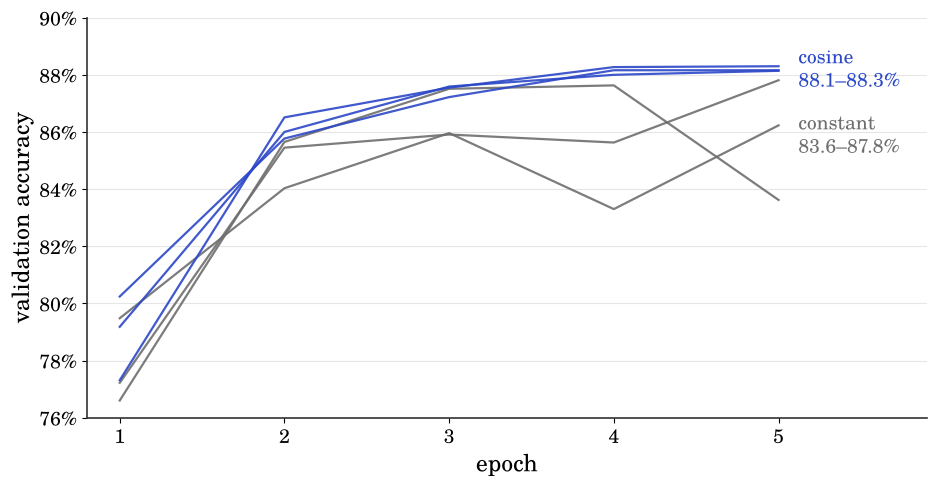

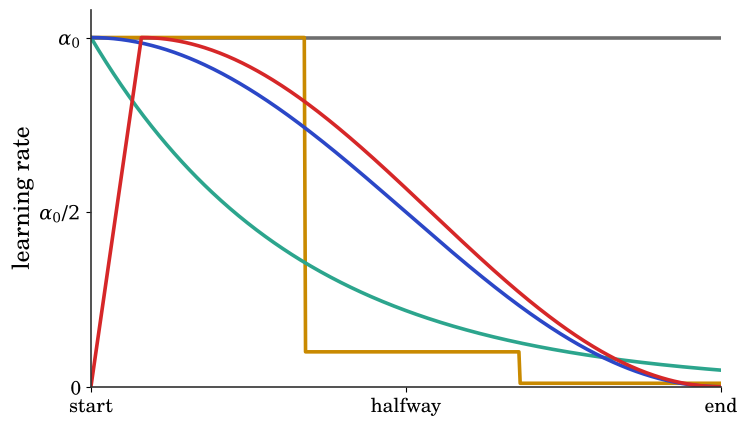

In [8]:
P6 = 'results/e6_lr_decay.json'
STEPS_PER_EPOCH = math.ceil(len(Xtr) / 64); T6 = 5 * STEPS_PER_EPOCH
SCHED = {'constant': None,
         'step': lambda opt: torch.optim.lr_scheduler.LambdaLR(opt, lambda s: 0.1 ** (s // (2 * STEPS_PER_EPOCH))),
         'cosine': lambda opt: torch.optim.lr_scheduler.LambdaLR(opt, lambda s: 0.5 * (1 + math.cos(math.pi * s / T6)))}
if need(P6):
    e6 = {k: [train(lambda p: torch.optim.SGD(p, lr=0.1), epochs=5, seed=s, sched_fn=f)['val'] for s in range(3)] for k, f in SCHED.items()}
    save_json(e6, P6)
e6 = load_json(P6)
for k in SCHED:
    va = np.array([[v[1] for v in r] for r in e6[k]])
    print(f"{k:9s} final val acc per seed: {np.round(va[:, -1]*100, 1)}  mean {va[:, -1].mean()*100:.1f}%   by epoch: {np.round(va.mean(0)*100, 1)}")


def setup_decay(ax):
    ax.set_xlim(0.8, 5.9); ax.set_ylim(0.76, 0.90); ax.set_xticks([1, 2, 3, 4, 5]); ax.set_xlabel('epoch')
    ax.set_ylabel('validation accuracy'); ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0, decimals=0))
    ax.grid(axis='y', color='#E6E6E6')


def decay_layer(k, color):
    def draw(ax):
        va = np.array([[v[1] for v in r] for r in e6[k]]); e = np.arange(1, 6)
        for row in va: ax.plot(e, row, '-', color=color, lw=1.6, alpha=0.9)
        ax.text(5.12, va[:, -1].mean(), f'{k}\n{va[:, -1].min()*100:.1f}–{va[:, -1].max()*100:.1f}%', color=color, fontsize=14, va='center')
    return draw


layered('l08_lr_decay', (10, 5.0), [0.1, 0.15, 0.84, 0.8], setup_decay, [('constant', decay_layer('constant', GRAY)), ('cosine', decay_layer('cosine', BLUE))])

# learning-rate schedules (pure math, no training)
t = np.linspace(0, 1, 500)
SCH = {'constant': np.full_like(t, 1.0), 'step decay': 0.1 ** np.floor(t / 0.34), 'exponential': 0.97 ** (t * 100),
       'cosine': 0.5 * (1 + np.cos(np.pi * t)), 'warmup + cosine': np.where(t < 0.08, t / 0.08, 0.5 * (1 + np.cos(np.pi * (t - 0.08) / 0.92)))}
SCOL = {'constant': GRAY, 'step decay': GOLD, 'exponential': TEAL, 'cosine': BLUE, 'warmup + cosine': RED}


def setup_sched(ax):
    ax.set_xlim(0, 1.0); ax.set_ylim(0, 1.08); ax.set_xticks([0, 0.5, 1]); ax.set_xticklabels(['start', 'halfway', 'end'])
    ax.set_yticks([0, 0.5, 1]); ax.set_yticklabels(['0', r'$\alpha_0/2$', r'$\alpha_0$']); ax.set_ylabel('learning rate')


def sched_layer(k):
    def draw(ax):
        ax.plot(t, SCH[k], color=SCOL[k], lw=2.6)
        pass
    return draw


layered('l08_schedules', (7.5, 4.6), [0.13, 0.13, 0.84, 0.82], setup_sched, [(k, sched_layer(k)) for k in SCH])

## Experiment 7 · Saddles vs minima: how often is a random critical point a minimum?
At a critical point (gradient = 0) the curvature in N directions is described by an N×N symmetric matrix (the Hessian).
It is a minimum only if the surface curves **up** in every direction (all eigenvalues > 0).
Coin-flip intuition: each direction curves up with probability ½, so P(minimum) = (½)ᴺ.
Random symmetric matrices (Gaussian orthogonal ensemble) are even stingier, because their eigenvalues repel each other.

N= 1  coin flips (1/2)^N = 0.50000   random matrices: 0.49991  (99982 of 200,000)
N= 2  coin flips (1/2)^N = 0.25000   random matrices: 0.14673  (29346 of 200,000)
N= 3  coin flips (1/2)^N = 0.12500   random matrices: 0.02504  (5008 of 200,000)
N= 4  coin flips (1/2)^N = 0.06250   random matrices: 0.00257  (513 of 200,000)
N= 5  coin flips (1/2)^N = 0.03125   random matrices: 0.00010  (20 of 200,000)
N= 6  coin flips (1/2)^N = 0.01562   random matrices: 0.00000  (0 of 200,000)
N= 8  coin flips (1/2)^N = 0.00391   random matrices: 0.00000  (0 of 200,000)
N=10  coin flips (1/2)^N = 0.00098   random matrices: 0.00000  (0 of 200,000)
Our MLP has N = 101,770 weights: (1/2)^N = 10^ -30,636


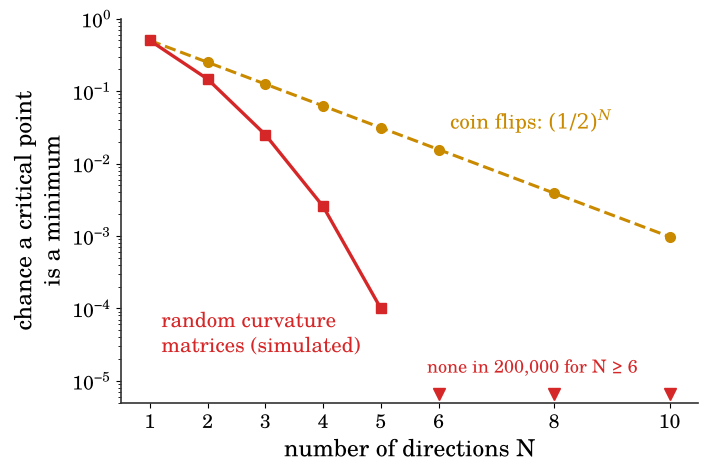

In [9]:
rng = np.random.default_rng(0)
NS_, TRIALS = [1, 2, 3, 4, 5, 6, 8, 10], 200000
frac = []
for n in NS_:
    hits, done = 0, 0
    while done < TRIALS:
        b = min(20000, TRIALS - done); M = rng.standard_normal((b, n, n)); M = (M + M.transpose(0, 2, 1)) / 2
        hits += int((np.linalg.eigvalsh(M)[:, 0] > 0).sum()); done += b
    frac.append(hits / TRIALS)
for n, fr in zip(NS_, frac): print(f'N={n:2d}  coin flips (1/2)^N = {0.5**n:.5f}   random matrices: {fr:.5f}  ({int(round(fr*TRIALS))} of {TRIALS:,})')
print('Our MLP has N = 101,770 weights: (1/2)^N = 10^', f'{-101770*math.log10(2):,.0f}')
save_json({'N': NS_, 'coin': [0.5 ** n for n in NS_], 'random_matrix': frac, 'trials': TRIALS}, 'results/e7_saddles.json')


def setup_saddle(ax):
    ax.set_yscale('log'); ax.set_xlim(0.5, 10.5); ax.set_ylim(5e-6, 1); ax.set_xticks(NS_)
    ax.set_xlabel('number of directions N'); ax.set_ylabel('chance a critical point\nis a minimum')


def coin(ax):
    ax.plot(NS_, [0.5 ** n for n in NS_], 'o--', color=GOLD, lw=2.2, ms=7); ax.text(6.2, 0.5 ** 6 * 1.9, r'coin flips: $(1/2)^N$', color=GOLD, fontsize=15)


def rmat(ax):
    xs = [n for n, fr in zip(NS_, frac) if fr > 0]; ys = [fr for fr in frac if fr > 0]
    ax.plot(xs, ys, 's-', color=RED, lw=2.4, ms=7)
    zero = [n for n, fr in zip(NS_, frac) if fr == 0]
    ax.plot(zero, [6.5e-6] * len(zero), 'v', color=RED, ms=9)
    if zero: ax.text(zero[0] - 0.2, 1.3e-5, f'none in {TRIALS:,} for N ≥ {zero[0]}', color=RED, fontsize=13)
    ax.text(1.2, 2.5e-5, 'random curvature\nmatrices (simulated)', color=RED, fontsize=15)


layered('l08_saddles', (7.5, 4.8), [0.2, 0.15, 0.77, 0.8], setup_saddle, [('coin', coin), ('rmat', rmat)])

## All the numbers used on the slides

In [10]:
summary = {
    'hook': {str(lr): {'diverged': e1[str(lr)]['diverged'], 'steps_logged': len(e1[str(lr)]['losses']), 'val_acc': e1[str(lr)]['val'][-1][1]} for lr in LRS_HOOK},
    'batch_race': {str(bs): {'lr': lr, 'steps': float(np.mean([r['steps'] for r in e2[str(bs)]])), 'epochs': float(np.mean([r['epochs'] for r in e2[str(bs)]])),
                             'val_acc': float(np.mean([r['final'] for r in e2[str(bs)]]))} for bs, lr in RACE},
    'lr_sweep_best': {k: {'lr': BEST[k], 'val_acc': max(v)} for k, v in e5a.items()},
    'optimizer_race_final': {k: float(np.mean([r['val'][-1][1] for r in e5b[k]])) for k in OPTS},
    'decay_final': {k: [r[-1][1] for r in e6[k]] for k in SCHED},
    'ravine': {k: float(np.linalg.norm(paths[k][-1])) for k in paths},
    'saddles': dict(zip(map(str, NS_), frac)),
}
save_json(summary, 'results/summary.json')
print(json.dumps(summary, indent=1))

{
 "hook": {
  "0.001": {
   "diverged": false,
   "steps_logged": 1564,
   "val_acc": 0.7413
  },
  "0.1": {
   "diverged": false,
   "steps_logged": 1564,
   "val_acc": 0.8565
  },
  "1.0": {
   "diverged": false,
   "steps_logged": 1564,
   "val_acc": 0.2831
  }
 },
 "batch_race": {
  "50000": {
   "lr": 0.3,
   "steps": 32.0,
   "epochs": 32.0,
   "val_acc": 0.7381333333333334
  },
  "1000": {
   "lr": 0.3,
   "steps": 1601.3333333333333,
   "epochs": 32.026666666666664,
   "val_acc": 0.8872666666666666
  },
  "64": {
   "lr": 0.3,
   "steps": 9061.333333333334,
   "epochs": 11.598506666666665,
   "val_acc": 0.8767
  },
  "1": {
   "lr": 0.003,
   "steps": 14743.666666666666,
   "epochs": 0.2948733333333333,
   "val_acc": 0.8355666666666667
  }
 },
 "lr_sweep_best": {
  "SGD": {
   "lr": 0.1,
   "val_acc": 0.8565
  },
  "Momentum": {
   "lr": 0.01,
   "val_acc": 0.8642
  },
  "RMSProp": {
   "lr": 0.001,
   "val_acc": 0.8637
  },
  "Adam": {
   "lr": 0.001,
   "val_acc": 0.8675
  }